In [63]:
# Import libraries
import cv2
import numpy as np
import matplotlib.pyplot as plt

Text(0.5, 1.0, 'Face')

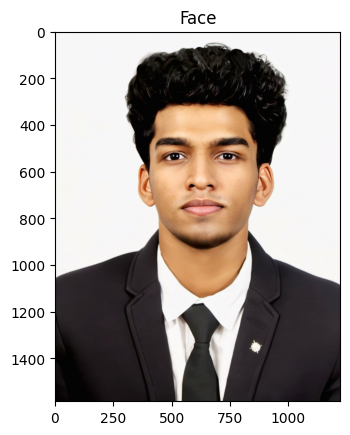

In [64]:
# Load the Face Image
faceImage = cv2.imread('MYPASSPORTIMG.jpeg')
plt.imshow(faceImage[:,:,::-1]);plt.title("Face")


In [65]:
faceImage.shape

(1584, 1224, 3)

In [66]:
#resized_faceImage.shape
faceImage.shape

(1584, 1224, 3)

Text(0.5, 1.0, 'glassPNG')

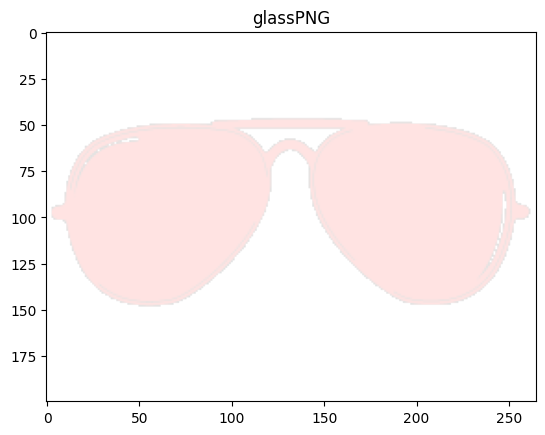

In [67]:
# Load the Sunglass image with Alpha channel
# (http://pluspng.com/sunglass-png-1104.html)
glassPNG = cv2.imread('glass.png',-1)
plt.imshow(glassPNG[:,:,::-1]);plt.title("glassPNG")

image Dimension =(140, 550, 4)


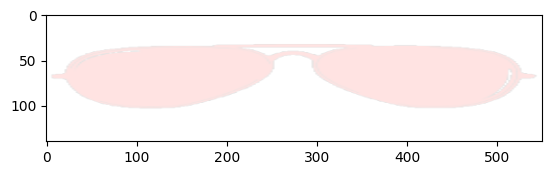

In [68]:
# Resize the image to fit over the eye region
glassPNG = cv2.resize(glassPNG, (550, 140))

plt.imshow(glassPNG[:, :, ::-1])
print("image Dimension ={}".format(glassPNG.shape))

In [69]:
# Separate the Color and alpha channels
glassBGR = glassPNG[:,:,0:3]
glassMask1 = glassPNG[:,:,3]

Text(0.5, 1.0, 'Sunglass Alpha channel')

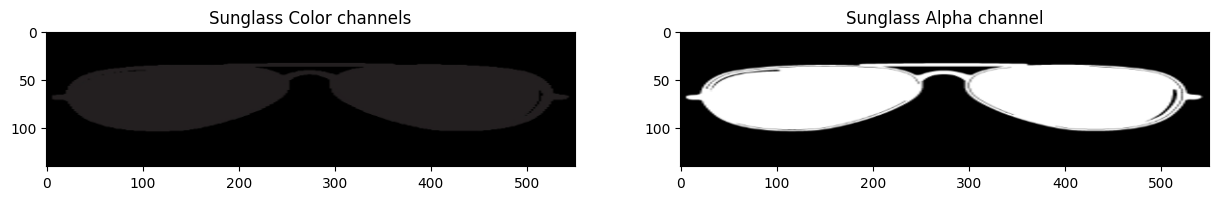

In [70]:
# Display the images for clarity
plt.figure(figsize=[15,15])
plt.subplot(121);plt.imshow(glassBGR[:,:,::-1]);plt.title('Sunglass Color channels')
plt.subplot(122);plt.imshow(glassMask1,cmap='gray');plt.title('Sunglass Alpha channel')

(np.float64(-0.5), np.float64(1223.5), np.float64(1583.5), np.float64(-0.5))

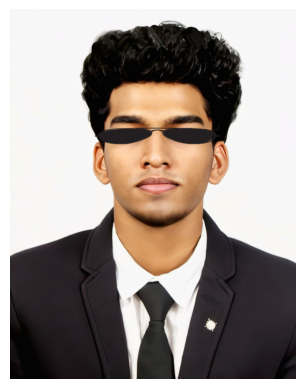

In [79]:

# Make a copy
faceWithGlassesNaive = faceImage.copy()

# Set the sunglasses position
x = 356
y = 475

h, w = glassBGR.shape[:2]

# Get the region of interest
roi = faceWithGlassesNaive[y:y+h, x:x+w]

# Apply the alpha mask
alpha = glassMask1[:, :, None] / 255.0

faceWithGlassesNaive[y:y+h, x:x+w] = (
    glassBGR * alpha + roi * (1 - alpha)
).astype('uint8')

plt.imshow(faceWithGlassesNaive[:, :, ::-1])
plt.axis('off')


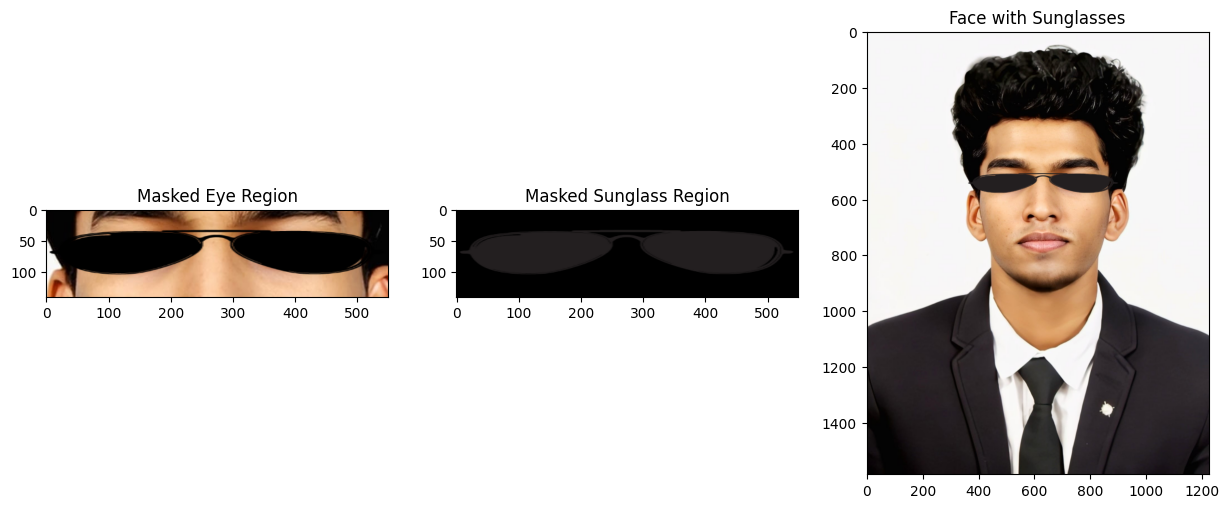

In [80]:

# Make the mask 3-channel
glassMask = cv2.merge((glassMask1, glassMask1, glassMask1))

# Normalize mask values to [0, 1]
glassMask = glassMask.astype(np.float32) / 255.0

# Convert images to float for arithmetic operations
glassBGR_float = glassBGR.astype(np.float32)

# Make a copy
faceWithGlassesArithmetic = faceImage.copy()

# Initial glasses position
x = 356
y = 475
h, w = glassBGR.shape[:2]

# Get the eye region
eyeROI = faceWithGlassesArithmetic[y:y+h, x:x+w].astype(np.float32)

# Apply the mask
maskedEye = eyeROI * (1 - glassMask)
maskedGlass = glassBGR_float * glassMask

# Combine the face and glasses
eyeRoiFinal = cv2.add(maskedEye, maskedGlass)
eyeRoiFinal = np.clip(eyeRoiFinal, 0, 255).astype(np.uint8)

# Place the result onto the face
faceWithGlassesArithmetic[y:y+h, x:x+w] = eyeRoiFinal

# Display results
plt.figure(figsize=[15, 6])

plt.subplot(131)
plt.imshow(maskedEye.astype(np.uint8)[:, :, ::-1])
plt.title("Masked Eye Region")

plt.subplot(132)
plt.imshow(maskedGlass.astype(np.uint8)[:, :, ::-1])
plt.title("Masked Sunglass Region")

plt.subplot(133)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("Face with Sunglasses")

plt.show()


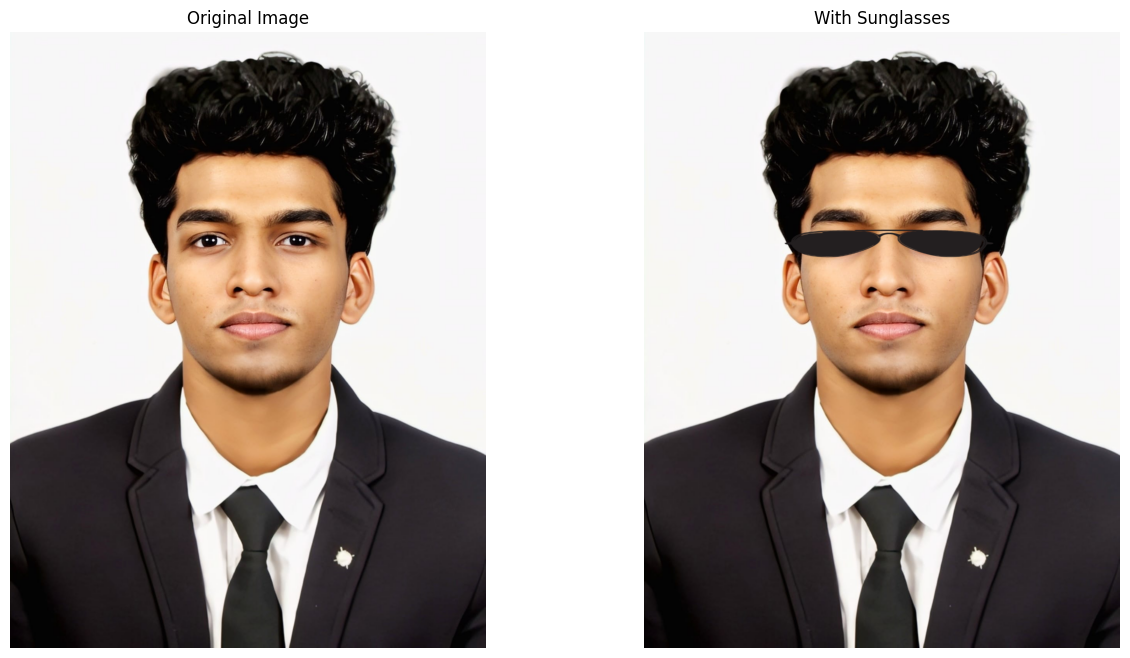

In [81]:

# Display the final result
plt.figure(figsize=[15, 8])

plt.subplot(121)
plt.imshow(faceImage[:, :, ::-1])
plt.title("Original Image")
plt.axis('off')

plt.subplot(122)
plt.imshow(faceWithGlassesArithmetic[:, :, ::-1])
plt.title("With Sunglasses")
plt.axis('off')

plt.show()
